In [1]:
import tensorflow as tf
import keras
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.21.0
Keras: 3.15.1


In [6]:

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
import matplotlib.pyplot as plt

from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight


In [7]:

# Load Fashion-MNIST dataset

(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

NUM_CLASSES = len(class_names)

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)
print("Number of classes:", NUM_CLASSES)


Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
Number of classes: 10


In [8]:

# Split training and testing data (80:20)

X = np.concatenate((X_train, X_test))
y = np.concatenate((y_train, y_test))

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Split validation data (15% of training data)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


Training: (47600, 28, 28)
Validation: (8400, 28, 28)
Testing: (14000, 28, 28)


In [9]:

# Normalize pixel values between 0 and 1

X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add grayscale channel dimension

X_train = np.expand_dims(X_train, axis=-1)
X_val = np.expand_dims(X_val, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)


Training shape: (47600, 28, 28, 1)
Validation shape: (8400, 28, 28, 1)
Testing shape: (14000, 28, 28, 1)


In [10]:

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:", class_weights)


Class weights: {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0, 5: 1.0, 6: 1.0, 7: 1.0, 8: 1.0, 9: 1.0}


In [11]:

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="image_augmentation")


In [12]:

model = keras.Sequential([

    layers.Input(shape=(28, 28, 1)),

    # Data augmentation
    augmentation,

    # Convolution block 1
    layers.Conv2D(32, kernel_size=3,
                  padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    # Convolution block 2
    layers.Conv2D(64, kernel_size=3,
                  padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    # Convolution block 3
    layers.Conv2D(128, kernel_size=3,
                  padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    # Classification layers
    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.5),

    layers.Dense(NUM_CLASSES, activation="softmax")
])


In [13]:

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ image_augmentation            │ (None, 28, 28, 1)     │            0 │
│ (Sequential)                  │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d (Conv2D)               │ (None, 28, 28, 32)    │          320 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 14, 14, 32)    │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_1 (Conv2D)             │ (None, 14, 14, 64)    │       18,496 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d_1               │ (None, 7, 7, 64)      │            0 │
│ (MaxPooling2D)                │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_2 (Conv2D)             │ (None, 7, 7, 128)     │       73,856 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d_2               │ (None, 3, 3, 128)     │            0 │
│ (MaxPooling2D)                │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ flatten (Flatten)             │ (None, 1152)          │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense (Dense)                 │ (None, 128)           │      147,584 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dropout (Dropout)             │ (None, 128)           │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_1 (Dense)               │ (None, 10)            │        1,290 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 241,546 (943.54 KB)

 Trainable params: 241,546 (943.54 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)


In [15]:

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)


Epoch 1/30
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.6895 - loss: 0.8438 - val_accuracy: 0.7661 - val_loss: 0.5894 - learning_rate: 0.0010
Epoch 2/30
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.7828 - loss: 0.5925 - val_accuracy: 0.8361 - val_loss: 0.4506 - learning_rate: 0.0010
Epoch 3/30
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.8114 - loss: 0.5173 - val_accuracy: 0.8492 - val_loss: 0.4072 - learning_rate: 0.0010
Epoch 4/30
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.8280 - loss: 0.4734 - val_accuracy: 0.8656 - val_loss: 0.3618 - learning_rate: 0.0010
Epoch 5/30
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.8398 - loss: 0.4432 - val_accuracy: 0.8704 - val_loss: 0.3585 - learning_rate: 0.0010
Epoch 6/30
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.8474 - loss: 0.4201 - val_accuracy: 0.8626 - val_loss: 0.3785 - learning_rate: 0.0010
Epoch 7/30
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accura

In [16]:

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=32
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", round(test_accuracy * 100, 2))


438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9007 - loss: 0.2725
Test Loss: 0.2725241482257843
Test Accuracy: 0.9007142782211304
Test Accuracy (%): 90.07


In [17]:

y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Actual labels:", y_test[:10])
print("Predicted labels:", y_pred[:10])

print("Predicted classes:")
for i in range(10):
    print(class_names[y_pred[i]])


438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Actual labels: [6 3 4 8 4 7 4 3 6 7]
Predicted labels: [2 3 4 8 4 7 4 3 6 7]
Predicted classes:
Pullover
Dress
Coat
Bag
Coat
Sneaker
Coat
Dress
Shirt
Sneaker


In [18]:

from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))


              precision    recall  f1-score   support

 T-shirt/top       0.84      0.85      0.84      1400
     Trouser       0.98      0.99      0.98      1400
    Pullover       0.82      0.89      0.85      1400
       Dress       0.89      0.91      0.90      1400
        Coat       0.85      0.83      0.84      1400
      Sandal       0.98      0.98      0.98      1400
       Shirt       0.73      0.66      0.70      1400
     Sneaker       0.94      0.97      0.96      1400
         Bag       0.98      0.98      0.98      1400
  Ankle boot       0.98      0.94      0.96      1400

    accuracy                           0.90     14000
   macro avg       0.90      0.90      0.90     14000
weighted avg       0.90      0.90      0.90     14000



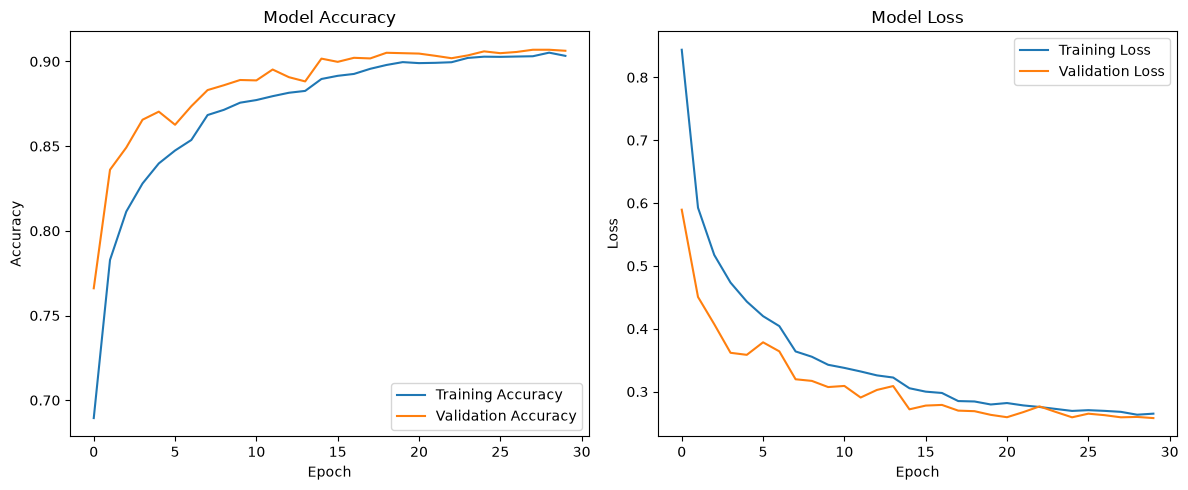

In [19]:

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [20]:

# Create Models directory
os.makedirs("../Models", exist_ok=True)

# Save trained CNN
model.save("../Models/fashion_cnn.keras")

# Save class names
with open("../Models/fashion_class_names.json", "w") as file:
    json.dump(class_names, file, indent=4)

# Save training history
history_df = pd.DataFrame(history.history)

history_df.to_csv(
    "../Models/day6_training_history.csv",
    index=False
)

print("CNN model saved successfully!")
print("Class names saved successfully!")
print("Training history saved successfully!")


CNN model saved successfully!
Class names saved successfully!
Training history saved successfully!
